# code_229 · Capstone: reference mechanics, sparse inverse data and a learned field operator

**Book:** section 43.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_43_GUIDE.md), [execution evidence](../CHAPTER_43_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_229).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Complete projects retain framing, data provenance, baseline comparisons, fitting/selection/calibration boundaries, independent assessment, measured resources and decision authority. Variable resource observations are stored separately from deterministic scientific RESULTS. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency is added. Two capstones reuse existing explicitly pinned checkpoints; the others generate every input internally.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8029;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8029


## Establish a reference problem before learning its forward or inverse map
 Solve the dimensionless fixed-end bar equation −(a(x)u′)′=f on[0,1], u(0)=u(1)=0, with a(x)=a0(1+0.2sin(2πx)) and a three-coefficient load family. Use conservative face fluxes and a tridiagonal banded solve; verify discrete equilibrium. For constant a and sinusoidal load, compare with the analytic solution on31/63/127 interior nodes and verify refinement. A separate scalar inverse estimates a0 from three noisy displacement sensors under a known load using bounded least squares. Independent sensor positions and a finer solve assess it. Multiplying both a0 and the load amplitude by the same factor preserves the displacement, exposing nonidentifiability if both are unknown. This reference family is not a field-validated structural model.


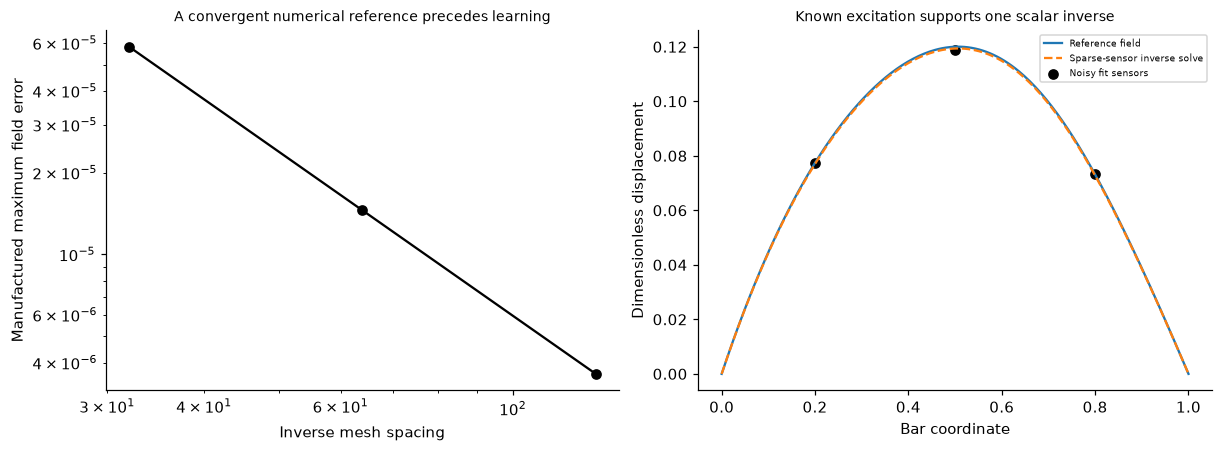

In [2]:
from scipy.linalg import solve_banded
from scipy.optimize import least_squares
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
def force(x,q):return q[0]+q[1]*np.sin(np.pi*x)+q[2]*np.sin(2*np.pi*x)
def solve(a0,q,n=63,constant=False):
    grid=np.linspace(0,1,n+2);h=1/(n+1);face=(grid[:-1]+grid[1:])/2;a=a0*(np.ones(n+1) if constant else 1+.2*np.sin(2*np.pi*face));diagonal=(a[:-1]+a[1:])/h**2;off=-a[1:-1]/h**2;band=np.zeros((3,n));band[1]=diagonal;band[0,1:]=off;band[2,:-1]=off;u=np.r_[0.,solve_banded((1,1),band,force(grid[1:-1],q)),0.];residual=-(a[1:]*(u[2:]-u[1:-1])-a[:-1]*(u[1:-1]-u[:-2]))/h**2-force(grid[1:-1],q);assert np.max(abs(residual))<1e-8;return grid,u
errors=[]
for n in [31,63,127]:
    grid,u=solve(1.4,[0,1,0],n,True);errors.append(float(np.max(abs(u-np.sin(np.pi*grid)/(1.4*np.pi**2)))))
assert errors[0]/errors[1]>3.8 and errors[1]/errors[2]>3.8;sensors=np.array([.2,.5,.8]);qtrue=np.array([1.,.3,.2]);grid,truth=solve(1.3,qtrue,255);observed=np.interp(sensors,grid,truth)+rng.normal(scale=.0005,size=3)
def sensor_residual(loga):
    x,u=solve(float(np.exp(loga[0])),qtrue,127);return np.interp(sensors,x,u)-observed
inverse=least_squares(sensor_residual,[np.log(1.)],bounds=([np.log(.3)],[np.log(3.)]));estimated=float(np.exp(inverse.x[0]));gx,gu=solve(estimated,qtrue,255);held_sensors=np.array([.35,.65]);held_error=float(np.sqrt(np.mean((np.interp(held_sensors,gx,gu)-np.interp(held_sensors,grid,truth))**2)));x1,u1=solve(1.3,qtrue,127);x2,u2=solve(2.6,2*qtrue,127);assert np.array_equal(u1,u2);RESULTS.update(reference_equation='-(a u_x)_x=f, fixed endpoint displacements',manufactured_interior_nodes=[31,63,127],manufactured_max_errors=errors,inverse_sensor_positions=sensors.tolist(),inverse_true_a0=1.3,inverse_estimated_a0=estimated,independent_sensor_RMSE=held_error,joint_load_stiffness_scale_counterexample_max_difference=float(np.max(abs(u1-u2))),joint_load_stiffness_not_identifiable_from_displacement_alone=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].loglog([32,64,128],errors,'o-',color='black');axes[0].set(xlabel='Inverse mesh spacing',ylabel='Manufactured maximum field error',title='A convergent numerical reference precedes learning');axes[1].plot(grid,truth,label='Reference field');axes[1].plot(gx,gu,'--',label='Sparse-sensor inverse solve');axes[1].scatter(sensors,observed,color='black',label='Noisy fit sensors');axes[1].set(xlabel='Bar coordinate',ylabel='Dimensionless displacement',title='Known excitation supports one scalar inverse');axes[1].legend(fontsize=6);plt.show()


## Train a residual PINN and a branch–trunk operator, keeping their information budgets explicit
 A hard-boundary PINN uses u=x(1−x)net(x); autograd differentiates its flux for the known a0=1.3/load case. Train 800 Adam updates on65 collocation points, then evaluate field error and residual on a separate 257-point grid. A separate source family contains 80 independent coefficient/load cases,64 fit and 16 development. An actual branch–trunk network receives eight load-function samples plus eight stiffness-function samples in its branch and an output coordinate in its trunk; train 600 updates against 31-node source reference fields. This original DeepONet-style implementation is not a pretrained physical model. A ridge inverse hybrid learns log stiffness from three source displacement sensors and known load-shape features, then calls the reference solver; it has measured response information unavailable to a pure forward operator. Do not rank their errors as equal-information forecasts.


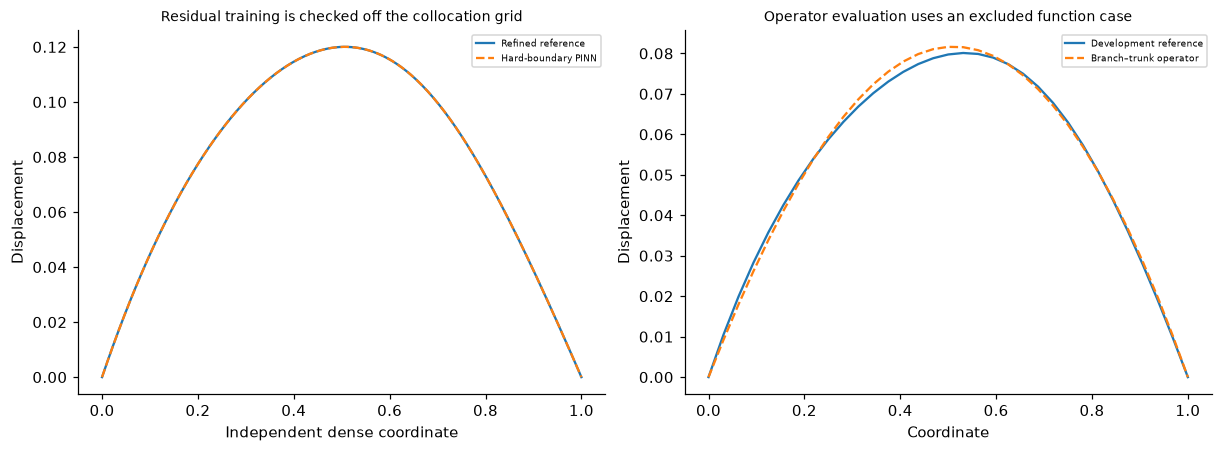

In [3]:
pinn=nn.Sequential(nn.Linear(1,24),nn.Tanh(),nn.Linear(24,24),nn.Tanh(),nn.Linear(24,1));optimizer=torch.optim.Adam(pinn.parameters(),lr=.01);collocation=torch.linspace(0,1,67)[1:-1,None].requires_grad_()
def pinn_field(x):return x*(1-x)*pinn(x)
def residual_at(x):
    u=pinn_field(x);du=torch.autograd.grad(u.sum(),x,create_graph=True)[0];a=1.3*(1+.2*torch.sin(2*torch.pi*x));flux=a*du;df=torch.autograd.grad(flux.sum(),x,create_graph=True)[0];f=qtrue[0]+qtrue[1]*torch.sin(torch.pi*x)+qtrue[2]*torch.sin(2*torch.pi*x);return -df-f
for _ in range(800):
    optimizer.zero_grad();loss=residual_at(collocation).square().mean();loss.backward();optimizer.step()
dense=torch.linspace(0,1,257)[:,None].requires_grad_();pu=pinn_field(dense).detach().numpy()[:,0];pres=float(residual_at(dense[1:-1]).detach().square().mean().sqrt());reference_grid,reference_u=solve(1.3,qtrue,255);pinn_rmse=float(np.sqrt(np.mean((pu-reference_u)**2)))
a0=rng.uniform(.8,1.8,80);loads=np.c_[rng.uniform(.7,1.3,80),rng.uniform(-.3,.3,80),rng.uniform(-.15,.15,80)];locations=np.linspace(0,1,8);branch_input=np.array([np.r_[force(locations,q),a*(1+.2*np.sin(2*np.pi*locations))] for a,q in zip(a0,loads)]);source_grid=np.linspace(0,1,33);fields=np.array([solve(a,q,31)[1] for a,q in zip(a0,loads)]);branch_scaler=StandardScaler().fit(branch_input[:64]);bx=torch.tensor(branch_scaler.transform(branch_input[:64]));xx=torch.tensor(source_grid[:,None]);targets=torch.tensor(fields[:64]);branch=nn.Sequential(nn.Linear(16,32),nn.Tanh(),nn.Linear(32,16));trunk=nn.Sequential(nn.Linear(1,32),nn.Tanh(),nn.Linear(32,16));optimizer=torch.optim.Adam(list(branch.parameters())+list(trunk.parameters()),lr=.01)
def operator_tensor(b,x):return (branch(b)@trunk(x).T)*x[:,0][None]*(1-x[:,0][None])
for _ in range(600):
    optimizer.zero_grad();loss=((operator_tensor(bx,xx)-targets)/.1).square().mean();loss.backward();optimizer.step()
def operator(a,q,points):
    b=np.array([np.r_[force(locations,qq),aa*(1+.2*np.sin(2*np.pi*locations))] for aa,qq in zip(a,q)])
    with torch.no_grad():return operator_tensor(torch.tensor(branch_scaler.transform(b)),torch.tensor(np.array(points)[:,None])).numpy()
def hybrid_features(a,q):
    output=[]
    for aa,qq in zip(a,q):
        x,u=solve(aa,qq,63);measurement=np.interp(sensors,x,u);output.append(np.r_[np.log(np.maximum(measurement,1e-8)),np.log(qq[0]),qq[1:]/qq[0]])
    return np.array(output)
hybrid_source=hybrid_features(a0[:64],loads[:64]);hybrid_scale=StandardScaler().fit(hybrid_source);hybrid=Ridge(alpha=.01).fit(hybrid_scale.transform(hybrid_source),np.log(a0[:64]));development_prediction=operator(a0[64:],loads[64:],source_grid);RESULTS.update(PINN_collocation_points=65,PINN_source_steps=800,PINN_dense_field_RMSE=pinn_rmse,PINN_independent_continuous_residual_RMS=pres,operator_source_cases=64,operator_development_cases=16,operator_source_interior_nodes=31,operator_source_steps=600,operator_development_field_RMSE=float(np.sqrt(np.mean((development_prediction-fields[64:])**2))),hybrid_has_three_measured_displacements=True,operator_is_own_branch_trunk_not_pretrained=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(reference_grid,reference_u,label='Refined reference');axes[0].plot(reference_grid,pu,'--',label='Hard-boundary PINN');axes[0].set(xlabel='Independent dense coordinate',ylabel='Displacement',title='Residual training is checked off the collocation grid');axes[0].legend(fontsize=6);axes[1].plot(source_grid,fields[64],label='Development reference');axes[1].plot(source_grid,development_prediction[0],'--',label='Branch–trunk operator');axes[1].set(xlabel='Coordinate',ylabel='Displacement',title='Operator evaluation uses an excluded function case');axes[1].legend(fontsize=6);plt.show()


## Audit new functions/grids and verify a proposed design independently
 Evaluate 24 untouched in-range functions on127 interior reference nodes and a65-point operator grid; interpolate the finer reference only for comparison. Also challenge stiffness 0.3 outside the source range. Report continuous-boundary satisfaction, field RMSE and an independently discretized flux residual separately. The hybrid receives three generated sensor measurements and known excitation, estimates stiffness, then solves; the operator receives the actual stiffness function for forward prediction. A surrogate proposes the smallest stiffness on a fixed 0.5–3.0 grid whose predicted maximum displacement is at most 0.08 for one fixed load. Verify that proposal with 255/511-interior-node reference solves and retain whether it passes. If it fails, search the same grid with the reference solver and record a repaired feasible design without retraining on the result. This is numerical verification within the declared bar law, not engineering approval. Time actual forward/solver workloads separately from deterministic RESULTS.


,reference_equation,manufactured_interior_nodes,manufactured_max_errors,inverse_sensor_positions,inverse_true_a0,inverse_estimated_a0,independent_sensor_RMSE,joint_load_stiffness_scale_counterexample_max_difference,joint_load_stiffness_not_identifiable_from_displacement_alone,PINN_collocation_points,...,final_operator_flux_residual_RMS_mean,out_of_range_a0,out_of_range_operator_field_RMSE,operator_boundary_max_abs,surrogate_proposed_design_a0,proposal_refined_reference_max_displacement,proposal_reference_mesh_difference,proposal_passes_declared_reference_limit,reference_grid_minimum_feasible_a0,verified_design_is_not_field_clearance
0,"-(a u_x)_x=f, fixed endpoint displacements","[31, 63, 127]","[5.815674401622728e-05, 1.4533931043309023e-05...","[0.2, 0.5, 0.8]",1.3,1.306945,0.000578,0.0,True,65,...,0.337065,0.3,0.157214,0.0,1.85,0.078936,1.703029e-07,True,1.85,True


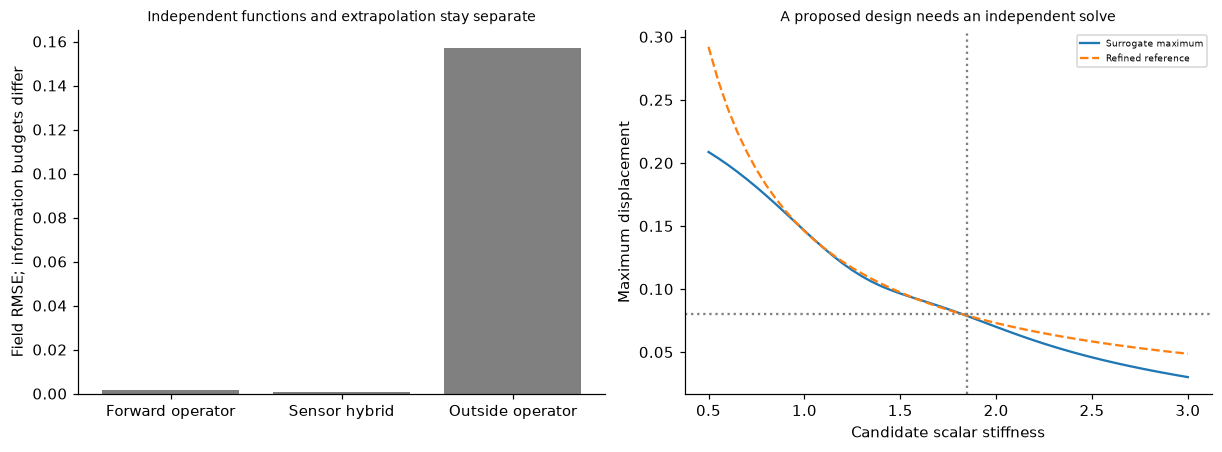

In [4]:
final_a=rng.uniform(.8,1.8,24);final_q=np.c_[rng.uniform(.7,1.3,24),rng.uniform(-.3,.3,24),rng.uniform(-.15,.15,24)];points=np.linspace(0,1,65);reference=np.array([np.interp(points,*solve(a,q,127)) for a,q in zip(final_a,final_q)]);prediction=operator(final_a,final_q,points);hybrid_a=np.exp(hybrid.predict(hybrid_scale.transform(hybrid_features(final_a,final_q))));hybrid_fields=np.array([np.interp(points,*solve(a,q,127)) for a,q in zip(hybrid_a,final_q)]);outside_a=np.full(8,.3);outside_q=final_q[:8];outside_reference=np.array([np.interp(points,*solve(a,q,127)) for a,q in zip(outside_a,outside_q)]);outside_prediction=operator(outside_a,outside_q,points);assert np.all(prediction[:,[0,-1]]==0);h=points[1]-points[0];face=(points[:-1]+points[1:])/2;flux_residual=[]
for aa,qq,u in zip(final_a,final_q,prediction):
    stiffness=aa*(1+.2*np.sin(2*np.pi*face));r=-(stiffness[1:]*(u[2:]-u[1:-1])-stiffness[:-1]*(u[1:-1]-u[:-2]))/h**2-force(points[1:-1],qq);flux_residual.append(float(np.sqrt(np.mean(r*r))))
grid_a=np.linspace(.5,3.,51);design_q=np.array([1.,.2,.1]);design_fields=operator(grid_a,np.tile(design_q,(51,1)),points);eligible=np.flatnonzero(design_fields.max(1)<=.08);assert len(eligible)>0;proposal=float(grid_a[eligible[0]]);xcoarse,ucoarse=solve(proposal,design_q,255);xfine,ufine=solve(proposal,design_q,511);mesh_difference=float(np.max(abs(np.interp(xcoarse,xfine,ufine)-ucoarse)));assert mesh_difference<1e-5;verified=bool(ufine.max()<=.08);feasible=[]
for aa in grid_a:
    gx,gu=solve(float(aa),design_q,511)
    if gu.max()<=.08:feasible.append(float(aa))
assert feasible;repaired=min(feasible);MEASUREMENTS={}
for name,fn in [('operator_24_fields',lambda:operator(final_a,final_q,points)),('reference_24_fields_127_interior',lambda:[solve(a,q,127) for a,q in zip(final_a,final_q)])]:
    fn();duration=[]
    for _ in range(5):
        start=time.perf_counter();fn();duration.append(time.perf_counter()-start)
    MEASUREMENTS[name]={'median_seconds':float(np.median(duration)),'repetitions':5}
RESULTS.update(independent_final_functions=24,operator_assessment_coordinates=65,reference_assessment_interior_nodes=127,final_operator_field_RMSE=float(np.sqrt(np.mean((prediction-reference)**2))),final_sensor_assisted_hybrid_field_RMSE=float(np.sqrt(np.mean((hybrid_fields-reference)**2))),final_operator_flux_residual_RMS_mean=float(np.mean(flux_residual)),out_of_range_a0=.3,out_of_range_operator_field_RMSE=float(np.sqrt(np.mean((outside_prediction-outside_reference)**2))),operator_boundary_max_abs=float(np.max(abs(prediction[:,[0,-1]]))),surrogate_proposed_design_a0=proposal,proposal_refined_reference_max_displacement=float(ufine.max()),proposal_reference_mesh_difference=mesh_difference,proposal_passes_declared_reference_limit=verified,reference_grid_minimum_feasible_a0=repaired,verified_design_is_not_field_clearance=True);display(pd.DataFrame([RESULTS]));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['Forward operator','Sensor hybrid','Outside operator'],[RESULTS['final_operator_field_RMSE'],RESULTS['final_sensor_assisted_hybrid_field_RMSE'],RESULTS['out_of_range_operator_field_RMSE']],color='.5');axes[0].set(ylabel='Field RMSE; information budgets differ',title='Independent functions and extrapolation stay separate');reference_max=np.array([solve(float(a),design_q,511)[1].max() for a in grid_a]);axes[1].plot(grid_a,design_fields.max(1),label='Surrogate maximum');axes[1].plot(grid_a,reference_max,'--',label='Refined reference');axes[1].axhline(.08,color='.5',linestyle=':');axes[1].axvline(proposal,color='.5',linestyle=':');axes[1].set(xlabel='Candidate scalar stiffness',ylabel='Maximum displacement',title='A proposed design needs an independent solve');axes[1].legend(fontsize=6);plt.show()


In [5]:
summary={'example_id':'code_229','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual variable-stiffness bar reference solver with manufactured solution and mesh refinement', 'sparse-sensor scalar inverse stiffness estimation and explicit joint load-stiffness nonidentifiability', 'actual autograd residual PINN source-trained inverse hybrid and branch-trunk neural operator', 'independent-grid physical residual extrapolation and surrogate-proposed design verified by refined reference solves'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual variable-stiffness bar reference solver with manufactured solution and mesh refinement", "sparse-sensor scalar inverse stiffness estimation and explicit joint load-stiffness nonidentifiability", "actual autograd residual PINN source-trained inverse hybrid and branch-trunk neural operator", "independent-grid physical residual extrapolation and surrogate-proposed design verified by refined reference solves"], "elapsed_seconds": 1.627, "example_id": "code_229", "hardware": "Darwin arm64 CPU", "resource_measurements": {"operator_24_fields": {"median_seconds": 0.00022175000049173832, "repetitions": 5}, "reference_24_fields_127_interior": {"median_seconds": 0.0006730000022798777, "repetitions": 5}}, "results": {"PINN_collocation_points": 65, "PINN_dense_field_RMSE": 8.426028881206151e-06, "PINN_independent_continuous_residual_RMS": 0.005025711052893875, "PINN_source_steps": 800, "final_operator_field_RMSE": 0.001865930845812077, "fina